# Notebook 03: chemical species and reactions

This notebook reads the chemistry output of two `sim.exe` dumps through `Dump.particle_g_estimates()`, `Dump.reactions()` and `Dump.meso_species()`: particle-stage species yields as G-values (molecules per 100 eV), reaction firing counts, and the mesoscopic mean count per event.

Both dumps are tiny, seeded runs (10 keV electrons, **two events each**). Everything below is a **workflow demonstration**, not a converged result. Run the cells from top to bottom in a fresh kernel; edit `IRT_DUMP` and `MESO_DUMP` in the next cell to inspect other output.

**Two separate simulations.** `IRT_DUMP` is an IRT_syn run with the mesoscopic stage off; `MESO_DUMP` is a different IRT_syn + mesoscopic run (different seeds). They are **not one trajectory**: the particle-stage G-values and reactions come from the IRT dump only, and the mesoscopic counts from the meso dump only.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from g4utils.DnaChem import Dump

dev_dir = os.environ.get('DEV_DIR')
if not dev_dir:
    raise RuntimeError(
        'DEV_DIR is unset. Run ~/dotfiles/scripts/windows/setup-dev-env.ps1 and restart the shell before using this notebook.'
    )
DEV_DIR = Path(dev_dir)

DEFAULT_RUN_ROOT = (
    DEV_DIR / 'GEANT4' / 'SIM' / 'dnachem-min'
    / '.scratch' / 'tests'
    / '2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the'
)

# Edit these paths for different dumps (unprefixed, each with its own Manifest.json).
IRT_DUMP = DEFAULT_RUN_ROOT / 'irt'
MESO_DUMP = DEFAULT_RUN_ROOT / 'meso-spatial'

README_HINT = 'See notebooks/README.md ("Reproduce the runs") to regenerate the demonstration data.'

for name in ('particle_g_estimates', 'reactions', 'meso_species'):
    if not hasattr(Dump, name):
        raise ImportError(f'The installed G4Utils lacks Dump.{name}. {README_HINT}')
for p in (IRT_DUMP, MESO_DUMP):
    mf = p / 'Manifest.json'
    if not mf.is_file() or mf.stat().st_size == 0:
        raise FileNotFoundError(f'No usable Manifest.json at {mf}. Edit the path or regenerate. {README_HINT}')

irt = Dump.from_manifest(IRT_DUMP / 'Manifest.json')
meso = Dump.from_manifest(MESO_DUMP / 'Manifest.json')
for label, d in (('IRT dump', irt), ('Meso dump', meso)):
    m = d.manifest
    print(f'{label}: {d.path.resolve()}')
    print(f'  model={m.chemistryModel}, events={m.totalEvents}, '
          f'E_dep={m.totalEnergyDeposit_eV} eV, hand-over={m.handOverTime_ns} ns, has_meso_species={d.has_meso_species}')

IRT dump: C:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\irt
  model=IRT_syn, events=2, E_dep=20000 eV, hand-over=None ns, has_meso_species=False
Meso dump: C:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\meso-spatial
  model=IRT_syn+mesoscopic, events=2, E_dep=20000 eV, hand-over=5 ns, has_meso_species=True


## 1. Particle-stage G-values (IRT dump)

`particle_g_estimates()` returns one row per species and time. Two estimators of G (molecules per 100 eV) are kept side by side:

- `aggregate_energy_G = 100 * number / totalEnergyDeposit_eV`: total molecule count over the total energy deposited in the whole run.
- `mean_event_G = sumG / nEvent`: the mean of the per-event G.

`mean_event_G_sem` (standard error of the mean over events) is null unless `assume_valid_event_g=True`, which asserts that every event contributed to both moments and had a positive energy deposit; the CSV cannot prove that. Event independence is likewise assumed. **With two events the SEM is not meaningful**; it is shown only to demonstrate the column.

793 rows; times 1.00e-12 to 1.00e-06 s; 13 species; events=2, E_dep=20000 eV
Last recorded time:
Max |aggregate_energy_G - mean_event_G| over all rows: 0


,species,time_s,number,nEvent,aggregate_energy_G,mean_event_G,mean_event_G_sem
783,H,9.999990e-07,149,2,0.745,0.745,0.085
784,H2,9.999990e-07,147,2,0.735,0.735,0.015
785,H2O2,9.999990e-07,135,2,0.675,0.675,0.065
780,H3O+,9.999990e-07,470,2,2.350,2.350,0.1
786,HO2,9.999990e-07,10,2,0.050,0.050,0.01
787,HO2-,9.999990e-07,0,2,0.000,0.000,0.0
789,O,9.999990e-07,13,2,0.065,0.065,0.025
790,O-,9.999990e-07,0,2,0.000,0.000,0.0
791,O2,9.999990e-07,3,2,0.015,0.015,0.005
792,O2-,9.999990e-07,10,2,0.050,0.050,0.03


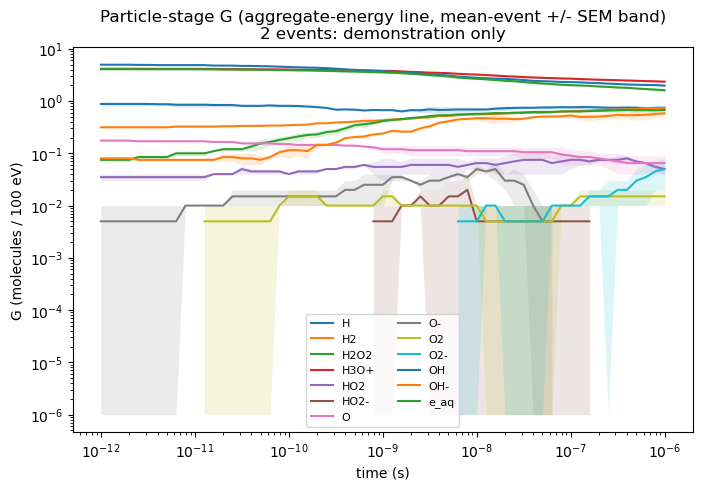

In [2]:
g = irt.particle_g_estimates(assume_valid_event_g=True)
print(f'{len(g)} rows; times {g.time_s.min():.2e} to {g.time_s.max():.2e} s; '
      f'{g.species.nunique()} species; events={g.totalEvents.iloc[0]}, E_dep={g.totalEnergyDeposit_eV.iloc[0]} eV')

cols = ['species', 'time_s', 'number', 'nEvent', 'aggregate_energy_G', 'mean_event_G', 'mean_event_G_sem']
last = g[g.time_s == g.time_s.max()].sort_values('species')
print('Last recorded time:')
display(last[cols])

fig, ax = plt.subplots(figsize=(8, 5))
for sp, sub in g.sort_values('time_s').groupby('species'):
    sub = sub[sub.aggregate_energy_G > 0]
    if sub.empty:
        continue
    line, = ax.plot(sub.time_s, sub.aggregate_energy_G, label=sp)
    sem = sub.mean_event_G_sem.astype(float)
    ax.fill_between(sub.time_s, (sub.mean_event_G - sem).clip(lower=1e-6), sub.mean_event_G + sem,
                    color=line.get_color(), alpha=0.15, linewidth=0)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('time (s)'); ax.set_ylabel('G (molecules / 100 eV)')
ax.set_title('Particle-stage G (aggregate-energy line, mean-event +/- SEM band)\n2 events: demonstration only')
ax.legend(ncol=2, fontsize=8)
plt.show()

# The two estimators should agree closely for equal-energy events; show the largest gap.
gap = (g.aggregate_energy_G - g.mean_event_G).abs()
print(f'Max |aggregate_energy_G - mean_event_G| over all rows: {gap.max():.3g}')

## 2. Reaction firing counts (IRT dump)

`reactions()` returns raw counts of reactions fired, per reaction and time bin. **Coverage limits:** only the particle-based stage is recorded. Bulk/scavenger channels (the acid-base buffer, dissolved-O2 scavenging) are not in these counts, and the mesoscopic stage does not record which reaction fired. Counts are totals over all events in the dump, not per-event or per-100-eV values, and the time bins are those of the run (coarse by default).

96 rows, 26 distinct reactions, 7 time bins, events=2


,total count
reaction,
e_aq^-1 + °OH^0 -> OH^-1,228
H3O^1 + OH^-1 -> (no products),216
°OH^0 + °OH^0 -> H2O2^0,152
e_aq^-1 + H3O^1 -> H^0,142
°OH^0 + H^0 -> (no products),91
e_aq^-1 + H^0 -> H_2^0 + OH^-1,42
°OH^0 + OH^-1 -> O^-1,38
°O^0 + °OH^0 -> HO_2°^0,29
e_aq^-1 + e_aq^-1 -> H_2^0 + OH^-1 + OH^-1,28


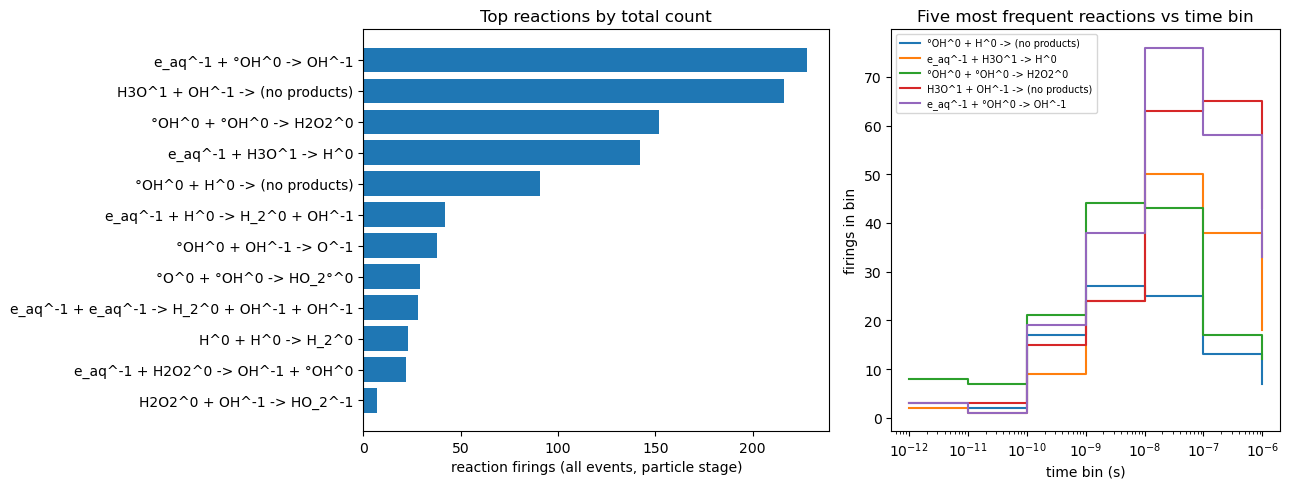

In [3]:
rx = irt.reactions()
print(f'{len(rx)} rows, {rx.reaction.nunique()} distinct reactions, {rx.time_s.nunique()} time bins, '
      f'events={rx.totalEvents.iloc[0]}')

totals = (rx.groupby('reaction')['count'].sum().sort_values(ascending=True))
display(totals.sort_values(ascending=False).rename('total count').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.2, 1]})
top = totals.tail(12)
axes[0].barh(top.index, top.values)
axes[0].set_xlabel('reaction firings (all events, particle stage)')
axes[0].set_title('Top reactions by total count')

for name in totals.tail(5).index:
    sub = rx[rx.reaction == name].sort_values('time_s')
    axes[1].step(sub.time_s, sub['count'], where='post', label=name)
axes[1].set_xscale('log')
axes[1].set_xlabel('time bin (s)'); axes[1].set_ylabel('firings in bin')
axes[1].set_title('Five most frequent reactions vs time bin')
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Mesoscopic mean count per event (meso dump)

`meso_species()` returns the summed count and `mean_count_per_event = count / totalEvents` of each species on the mesoscopic record grid, with raw species names (e.g. `°OH^0`, `e_aq^-1`) and times in ns. **These are molecule counts per event, not G-values**: there is no division by deposited energy, so they must not be put on the same axis as, or compared numerically with, the G of section 1 without that normalization. The stage starts at the **hand-over time** recorded in the manifest; the particle-stage species files stop there. The cell below plots only when `has_meso_species` is true (it is false for a run with the mesoscopic stage off, such as the IRT dump).

IRT dump  has_meso_species = False  (no mesoscopic plot expected)
Meso dump has_meso_species = True
712 rows, 13 species, events=2, hand-over=5 ns, chemistry end=1e+06 ns


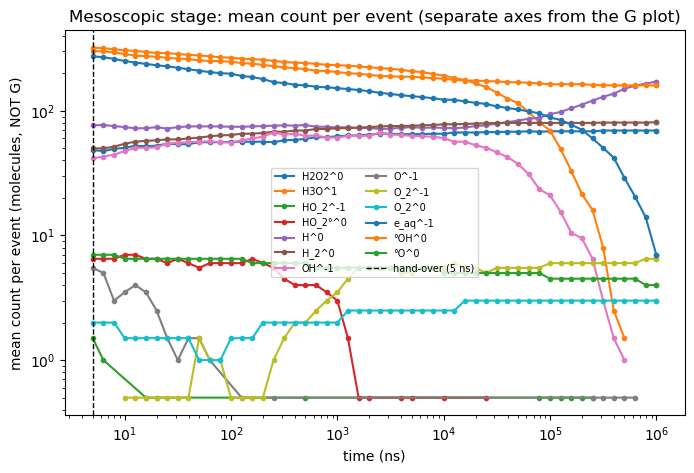

In [4]:
print(f'IRT dump  has_meso_species = {irt.has_meso_species}  (no mesoscopic plot expected)')
print(f'Meso dump has_meso_species = {meso.has_meso_species}')

if meso.has_meso_species:
    ms = meso.meso_species()
    hand_over = float(meso.manifest.handOverTime_ns)
    end_ns = ms.chemistryEndTime_ns.dropna().iloc[0] if ms.chemistryEndTime_ns.notna().any() else ms.time_ns.max()
    print(f'{len(ms)} rows, {ms.species.nunique()} species, events={ms.totalEvents.iloc[0]}, '
          f'hand-over={hand_over:g} ns, chemistry end={end_ns:g} ns')

    fig, ax = plt.subplots(figsize=(8, 5))
    for sp, sub in ms.sort_values('time_ns').groupby('species'):
        sub = sub[sub.mean_count_per_event > 0]
        if not sub.empty:
            ax.plot(sub.time_ns, sub.mean_count_per_event, marker='.', label=sp)
    ax.axvline(hand_over, color='k', linestyle='--', linewidth=1, label=f'hand-over ({hand_over:g} ns)')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('time (ns)'); ax.set_ylabel('mean count per event (molecules, NOT G)')
    ax.set_title('Mesoscopic stage: mean count per event (separate axes from the G plot)')
    ax.legend(ncol=2, fontsize=7)
    plt.show()
else:
    display(Markdown('The meso dump has no mesoscopic species output; nothing to plot.'))

## Reading notes

- **Two simulations, not one trajectory.** The IRT dump (particle stage only) and the meso dump (particle stage up to the hand-over, then the mesoscopic stage) were run with different seeds. Sections 1-2 use the first, section 3 the second. The meso dump's own particle stage ends at its hand-over time (5 ns) and is not stitched to the IRT run.
- **Normalization.** Section 1 is G (molecules per 100 eV, normalized by deposited energy); section 3 is molecules per event (normalized by event count only). The two are never plotted together; converting one to the other needs the per-event energy deposit, which is not done here.
- **Reaction coverage.** `reactions()` covers the particle-based stage only: no bulk/scavenger channels, and no identification of reactions fired in the mesoscopic stage.
- **Statistics.** Two events per run: SEM values and any shape differences are illustrative. The SEM relies on `assume_valid_event_g=True` (every event valid, independent events).
- **Not verified.** Species naming differs between the particle stage (`species`, normalized, e.g. `OH`) and the mesoscopic files (raw, e.g. `°OH^0`); no mapping between them is applied here.